# Phân Tích Dữ Liệu Thương Mại Điện Tử (Olist E-Commerce)
**Môn học:** IT4930 - Nhập môn Khoa học Dữ liệu

---
### 📌 Mục tiêu phân tích:
1. **Kết hợp (Join) 3 tập dữ liệu:**
   - `olist_orders_dataset.csv`: Thông tin đơn hàng (trạng thái, thời gian đặt hàng, khách hàng).
   - `olist_order_items_dataset.csv`: Chi tiết từng mặt hàng trong đơn (giá bán, cước vận chuyển, sản phẩm).
   - `olist_products_dataset.csv`: Thuộc tính sản phẩm (danh mục, kích thước, khối lượng).
2. **Giải quyết 2 yêu cầu trong `description.txt`:**
   - **Yêu cầu 1:** Giá trị đơn hàng và số đơn thay đổi thế nào theo số tháng (Vẽ **Line Chart**).
   - **Yêu cầu 2:** Top 10 sản phẩm bán chạy nhất (Vẽ **Bar Chart**).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách hiển thị biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("Import thư viện thành công!")

Import thư viện thành công!


## 1. Đọc dữ liệu từ 3 file CSV
Load 3 tệp dữ liệu từ thư mục `data/` vào các DataFrame của Pandas.

In [2]:
# Đọc 3 file dữ liệu
df_orders = pd.read_csv('data/olist_orders_dataset.csv')
df_order_items = pd.read_csv('data/olist_order_items_dataset.csv')
df_products = pd.read_csv('data/olist_products_dataset.csv')

print(f"1. df_orders: {df_orders.shape[0]:,} dòng, {df_orders.shape[1]} cột")
print(f"2. df_order_items: {df_order_items.shape[0]:,} dòng, {df_order_items.shape[1]} cột")
print(f"3. df_products: {df_products.shape[0]:,} dòng, {df_products.shape[1]} cột")

1. df_orders: 99,441 dòng, 8 cột
2. df_order_items: 112,650 dòng, 7 cột
3. df_products: 32,951 dòng, 9 cột


In [3]:
# Xem trước một số dòng đầu của mỗi bảng
print("--- Orders Head ---")
display(df_orders.head(2))

print("--- Order Items Head ---")
display(df_order_items.head(2))

print("--- Products Head ---")
display(df_products.head(2))

--- Orders Head ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


--- Order Items Head ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


--- Products Head ---


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0


## 2. Kết hợp (Join) 3 tập dữ liệu
Thực hiện ghép 3 bảng dữ liệu:
- **Bước 1:** Ghép `df_order_items` với `df_orders` thông qua khóa chung `order_id` (sử dụng phương thức `inner join`).
- **Bước 2:** Ghép bảng kết quả với `df_products` thông qua khóa chung `product_id` (sử dụng `left join` để giữ lại toàn bộ chi tiết sản phẩm đã bán và bổ sung thông tin danh mục).

In [4]:
# Thực hiện Join 3 bảng
df_merged = df_order_items.merge(df_orders, on='order_id', how='inner')
df_merged = df_merged.merge(df_products, on='product_id', how='left')

print(f"Kích thước bảng dữ liệu sau khi join: {df_merged.shape[0]:,} dòng, {df_merged.shape[1]} cột")
print("\nDanh sách các cột:")
print(df_merged.columns.tolist())
df_merged.head(3)

Kích thước bảng dữ liệu sau khi join: 112,650 dòng, 22 cột

Danh sách các cột:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,order_delivered_customer_date,order_estimated_delivery_date,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,2017-09-20 23:43:48,2017-09-29 00:00:00,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,2017-05-12 16:04:24,2017-05-15 00:00:00,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,2018-01-22 13:19:16,2018-02-05 00:00:00,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0


## 3. Tiền xử lý dữ liệu
- Chuyển đổi cột `order_purchase_timestamp` thành kiểu dữ liệu thời gian (`datetime`).
- Tạo cột `year_month` (định dạng `YYYY-MM`) để phân nhóm theo tháng đặt hàng.

In [5]:
# Chuyển đổi sang datetime
df_merged['order_purchase_timestamp'] = pd.to_datetime(df_merged['order_purchase_timestamp'])

# Tạo cột năm-tháng (Period) và chuỗi YYYY-MM
df_merged['year_month'] = df_merged['order_purchase_timestamp'].dt.to_period('M')

min_date = df_merged['order_purchase_timestamp'].min()
max_date = df_merged['order_purchase_timestamp'].max()
print(f"Khoảng thời gian ghi nhận đơn hàng: Từ {min_date} đến {max_date}")

Khoảng thời gian ghi nhận đơn hàng: Từ 2016-09-04 21:15:19 đến 2018-09-03 09:06:57


## 4. Yêu cầu 1: Giá trị đơn hàng và số đơn thay đổi thế nào theo số tháng
Tiến hành tổng hợp số liệu theo từng tháng:
- **Số đơn (`order_count`):** Đếm số đơn hàng duy nhất bằng `order_id.nunique()`.
- **Tổng giá trị đơn hàng (`total_order_value`):** Tổng doanh số bán ra bằng `price.sum()`.
- **Giá trị trung bình mỗi đơn hàng (`avg_order_value`):** Doanh thu chia cho số đơn (`total_order_value / order_count`).
- Trực quan hóa xu hướng bằng **Line Chart**.

In [6]:
# Gom nhóm và tính toán các chỉ số theo tháng
monthly_summary = df_merged.groupby('year_month').agg(
    total_order_value=('price', 'sum'),
    order_count=('order_id', 'nunique'),
    total_items=('order_item_id', 'count')
).reset_index()

# Tính giá trị trung bình mỗi đơn
monthly_summary['avg_order_value'] = monthly_summary['total_order_value'] / monthly_summary['order_count']

# Tạo cột nhãn chuỗi hiển thị trên trục hoành
monthly_summary['year_month_str'] = monthly_summary['year_month'].astype(str)

print("Bảng tổng hợp giá trị đơn hàng và số đơn theo tháng:")
display(monthly_summary)

Bảng tổng hợp giá trị đơn hàng và số đơn theo tháng:

,year_month,total_order_value,order_count,total_items,avg_order_value,year_month_str
0,2016-09,267.36,3,6,89.120000,2016-09
1,2016-10,49507.66,308,363,160.739156,2016-10
2,2016-12,10.90,1,1,10.900000,2016-12
3,2017-01,120312.87,789,955,152.487795,2017-01
4,2017-02,247303.02,1733,1951,142.702262,2017-02
5,2017-03,374344.30,2641,3000,141.743393,2017-03
6,2017-04,359927.23,2391,2684,150.534182,2017-04
7,2017-05,506071.14,3660,4136,138.270803,2017-05
8,2017-06,433038.60,3217,3583,134.609450,2017-06
9,2017-07,498031.48,3969,4519,125.480343,2017-07


### Trực quan hóa Yêu cầu 1: Biểu đồ đường (Line Chart)
Chúng ta vẽ 2 biểu đồ trực quan:
1. **Biểu đồ đường trục tung kép (Dual Y-Axis Line Chart):** Thể hiện đồng thời mối quan hệ giữa Số lượng đơn hàng (trục Y bên trái) và Tổng giá trị đơn hàng (trục Y bên phải) qua các tháng.
2. **Hai biểu đồ đường con (Subplots):** Quan sát trực tiếp từng chỉ số một cách độc lập kèm theo chú thích điểm cực đại.

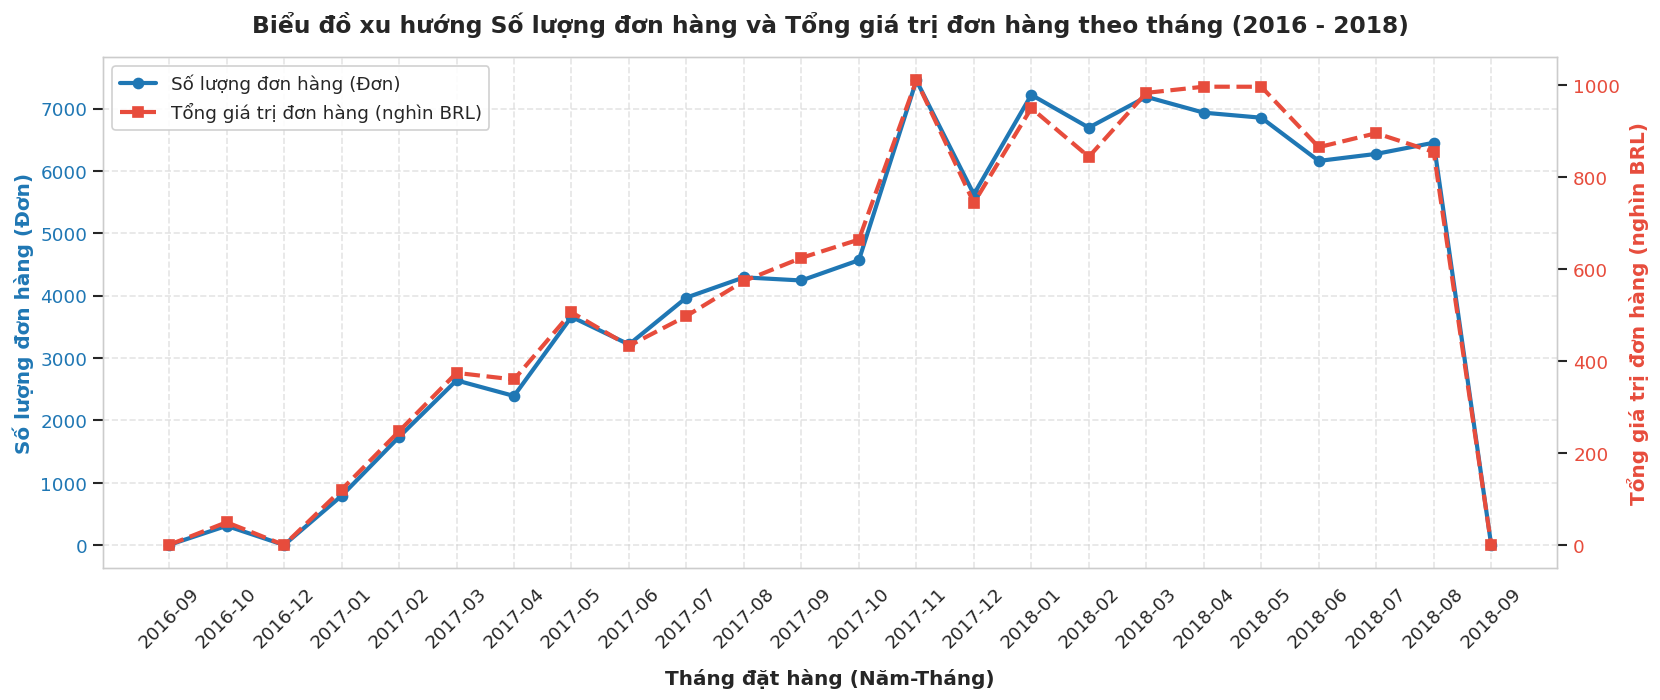

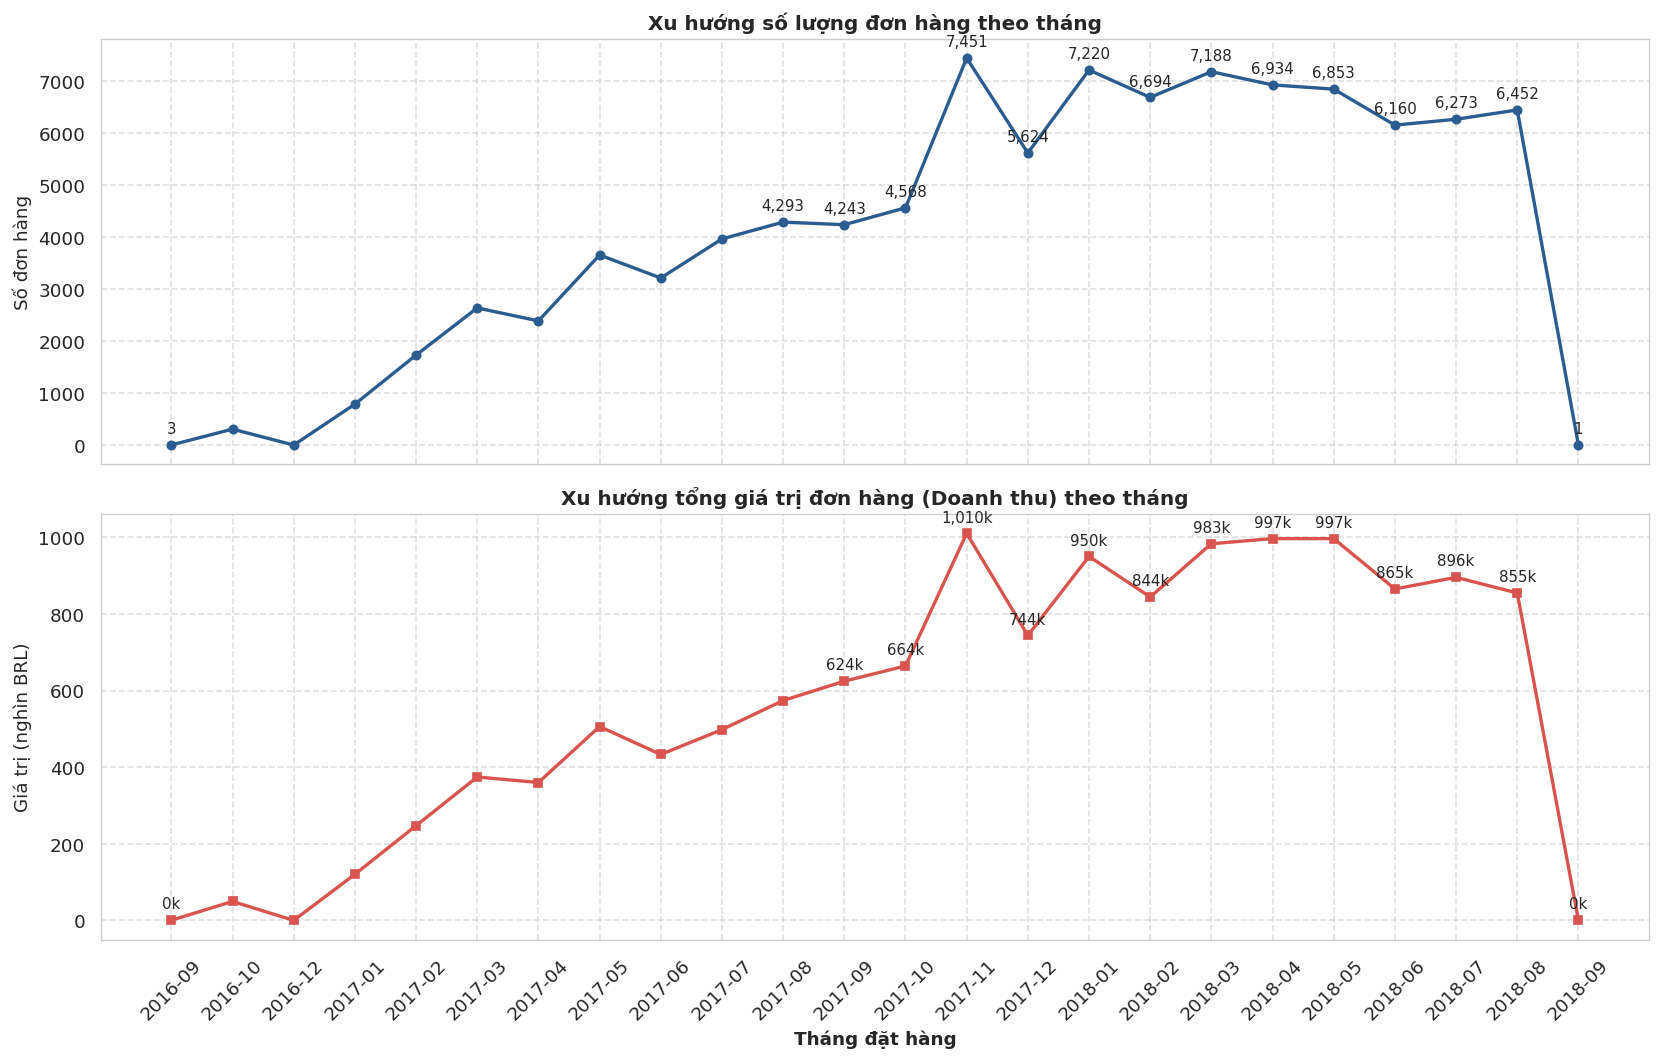

In [7]:
# 1. Biểu đồ đường trục tung kép (Dual Y-Axis Line Chart)
fig, ax1 = plt.subplots(figsize=(14, 6))

color_orders = '#1f77b4'  # Xanh dương
color_revenue = '#e74c3c' # Đỏ cam

# Đường 1: Số đơn hàng
line1 = ax1.plot(monthly_summary['year_month_str'], monthly_summary['order_count'], 
                 color=color_orders, marker='o', linewidth=2.5, markersize=6, label='Số lượng đơn hàng (Đơn)')
ax1.set_xlabel('Tháng đặt hàng (Năm-Tháng)', fontsize=12, fontweight='bold', labelpad=10)
ax1.set_ylabel('Số lượng đơn hàng (Đơn)', color=color_orders, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_orders)
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle='--', alpha=0.5)

# Đường 2: Tổng giá trị đơn hàng (Trục Y thứ 2)
ax2 = ax1.twinx()
line2 = ax2.plot(monthly_summary['year_month_str'], monthly_summary['total_order_value'] / 1e3, 
                 color=color_revenue, marker='s', linewidth=2.5, markersize=6, linestyle='--', label='Tổng giá trị đơn hàng (nghìn BRL)')
ax2.set_ylabel('Tổng giá trị đơn hàng (nghìn BRL)', color=color_revenue, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_revenue)
ax2.grid(False)

# Chú thích tổng hợp
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=11)

plt.title('Biểu đồ xu hướng Số lượng đơn hàng và Tổng giá trị đơn hàng theo tháng (2016 - 2018)', 
          fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 2. Hai biểu đồ đường chi tiết (Subplots)
fig, (ax_sub1, ax_sub2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Subplot 1: Số đơn
ax_sub1.plot(monthly_summary['year_month_str'], monthly_summary['order_count'], 
             color='#2b5c8f', marker='o', linewidth=2, markersize=5)
ax_sub1.set_title('Xu hướng số lượng đơn hàng theo tháng', fontsize=12, fontweight='bold')
ax_sub1.set_ylabel('Số đơn hàng', fontsize=11)
ax_sub1.grid(True, linestyle='--', alpha=0.6)
# Gắn nhãn giá trị các mốc tiêu biểu
for i, txt in enumerate(monthly_summary['order_count']):
    if txt > 4000 or i in [0, len(monthly_summary)-1]:
        ax_sub1.annotate(f"{txt:,}", (i, txt), textcoords="offset points", xytext=(0, 7), ha='center', fontsize=9)

# Subplot 2: Tổng giá trị đơn hàng
ax_sub2.plot(monthly_summary['year_month_str'], monthly_summary['total_order_value'] / 1e3, 
             color='#d9534f', marker='s', linewidth=2, markersize=5)
ax_sub2.set_title('Xu hướng tổng giá trị đơn hàng (Doanh thu) theo tháng', fontsize=12, fontweight='bold')
ax_sub2.set_xlabel('Tháng đặt hàng', fontsize=11, fontweight='bold')
ax_sub2.set_ylabel('Giá trị (nghìn BRL)', fontsize=11)
ax_sub2.tick_params(axis='x', rotation=45)
ax_sub2.grid(True, linestyle='--', alpha=0.6)
# Gắn nhãn giá trị
for i, txt in enumerate(monthly_summary['total_order_value']):
    if txt > 600000 or i in [0, len(monthly_summary)-1]:
        ax_sub2.annotate(f"{txt/1e3:,.0f}k", (i, txt/1e3), textcoords="offset points", xytext=(0, 7), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 5. Yêu cầu 2: Top 10 sản phẩm bán chạy nhất
- Tổng hợp số lượng sản phẩm bán ra (`order_item_id.count()`) theo từng `product_id`.
- Ghép tên danh mục (`product_category_name`) để biểu đồ mang nhiều thông tin thực tế hơn.
- Trực quan hóa Top 10 sản phẩm bán chạy nhất bằng **Bar Chart**.

In [8]:
# Gom nhóm theo product_id và product_category_name
top_products = df_merged.groupby(['product_id', 'product_category_name']).agg(
    total_quantity=('order_item_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Lấy Top 10 sản phẩm bán chạy nhất theo số lượng bán
top10_products_qty = top_products.sort_values(by='total_quantity', ascending=False).head(10).copy()

# Tạo nhãn hiển thị: rút gọn mã sản phẩm 8 ký tự đầu + tên danh mục
top10_products_qty['short_id'] = top10_products_qty['product_id'].str[:8] + '...'
top10_products_qty['display_label'] = top10_products_qty['short_id'] + ' (' + top10_products_qty['product_category_name'] + ')'

print("Top 10 sản phẩm bán chạy nhất:")
display(top10_products_qty[['product_id', 'product_category_name', 'total_quantity', 'total_revenue']])

Top 10 sản phẩm bán chạy nhất:


,product_id,product_category_name,total_quantity,total_revenue
21724,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,527,37608.90
19394,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,488,43025.56
8456,422879e10f46682990de24d770e7f83d,ferramentas_jardim,484,26577.22
7231,389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,392,21440.59
6950,368c6c730842d78016ad823897a372db,ferramentas_jardim,388,21056.80
10638,53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,373,20387.20
26545,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,343,47214.51
10665,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,37683.42
2743,154e7e31ebfa092203795c972e5804a6,beleza_saude,281,6325.19
7905,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,274,41082.60


### Trực quan hóa Yêu cầu 2: Biểu đồ cột (Bar Chart)
1. **Horizontal Bar Chart:** Thể hiện Top 10 sản phẩm bán chạy nhất (hiển thị kèm mã và ngành hàng).
2. **Vertical Bar Chart:** Thể hiện Top 10 ngành hàng / danh mục có số lượng bán cao nhất toàn hệ thống.

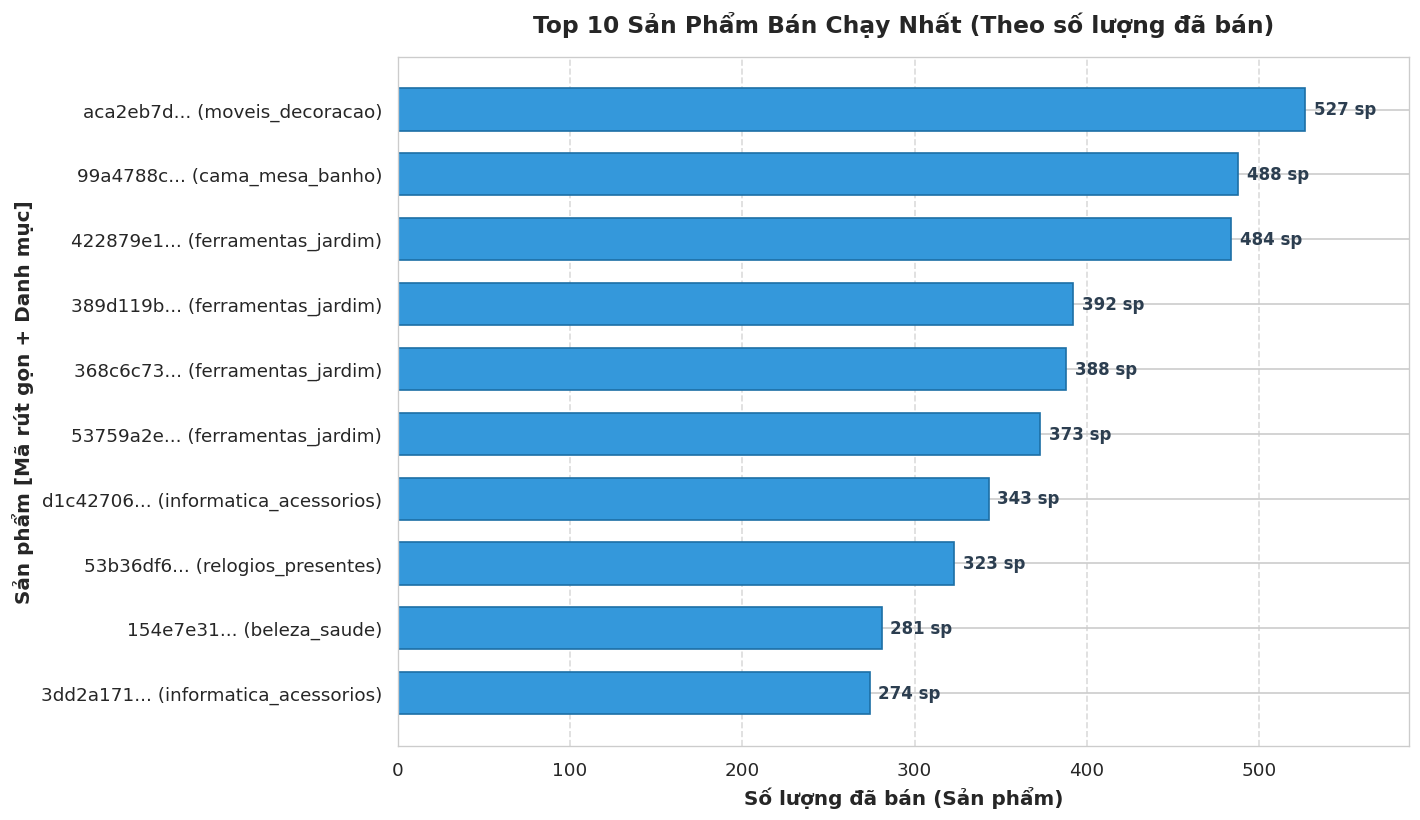

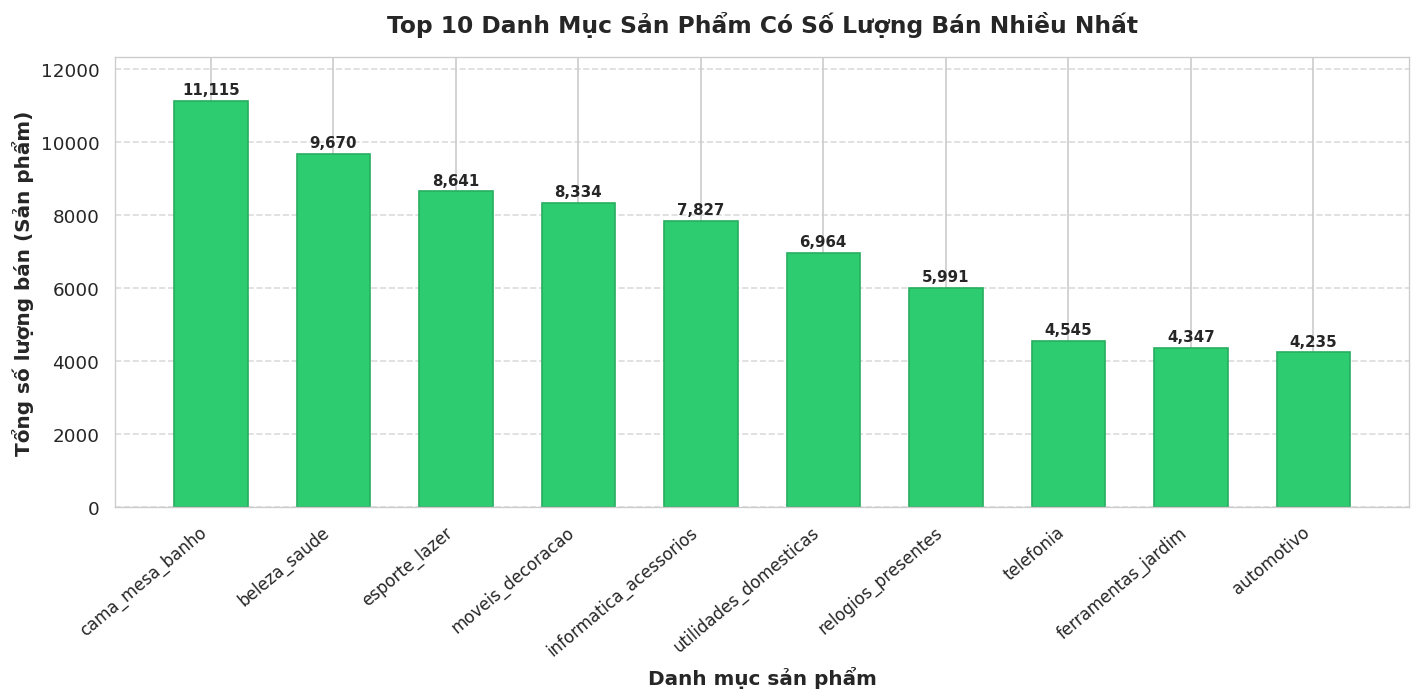

In [9]:
# 1. Bar Chart ngang cho Top 10 sản phẩm bán chạy nhất
plt.figure(figsize=(12, 7))
# Sắp xếp tăng dần để sản phẩm có số lượng cao nhất hiển thị ở trên cùng
top10_plot = top10_products_qty.sort_values(by='total_quantity', ascending=True)

bars = plt.barh(top10_plot['display_label'], top10_plot['total_quantity'], 
                color='#3498db', edgecolor='#1d6fa5', height=0.65)

# Ghi chú giá trị số lượng trên từng thanh
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2, 
             f"{int(width):,} sp", ha='left', va='center', fontsize=10, fontweight='bold', color='#2c3e50')

plt.title('Top 10 Sản Phẩm Bán Chạy Nhất (Theo số lượng đã bán)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số lượng đã bán (Sản phẩm)', fontsize=12, fontweight='bold')
plt.ylabel('Sản phẩm [Mã rút gọn + Danh mục]', fontsize=12, fontweight='bold')
plt.xlim(0, max(top10_plot['total_quantity']) + 60)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Biểu đồ cột đứng: Top 10 danh mục sản phẩm bán chạy nhất
top10_categories = df_merged.groupby('product_category_name')['order_item_id'].count().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 6))
cat_bars = plt.bar(top10_categories['product_category_name'], top10_categories['order_item_id'], 
                   color='#2ecc71', edgecolor='#27ae60', width=0.6)

# Ghi chú số lượng trên mỗi cột
for bar in cat_bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 100, 
             f"{int(height):,}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Top 10 Danh Mục Sản Phẩm Có Số Lượng Bán Nhiều Nhất', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Danh mục sản phẩm', fontsize=12, fontweight='bold')
plt.ylabel('Tổng số lượng bán (Sản phẩm)', fontsize=12, fontweight='bold')
plt.xticks(rotation=40, ha='right', fontsize=10)
plt.ylim(0, max(top10_categories['order_item_id']) + 1200)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 6. Tổng kết & Đánh giá kết quả

### Q&A
* **Câu hỏi 1: Giá trị đơn hàng và số đơn thay đổi thế nào theo số tháng?**
  - **Giai đoạn thử nghiệm (Cuối 2016):** Doanh nghiệp bắt đầu vận hành với lượng đơn còn rất khiêm tốn (dưới 350 đơn/tháng).
  - **Giai đoạn tăng trưởng bùng nổ (Năm 2017):** Số lượng đơn hàng tăng trưởng phi mã từ 789 đơn (tháng 1/2017) lên mức kỷ lục 7,451 đơn (tháng 11/2017), tương ứng doanh thu tăng từ 120,312 BRL lên 1,010,271 BRL.
  - **Đỉnh điểm doanh thu:** Tháng 11/2017 là tháng đạt kỷ lục về cả số đơn (7,451 đơn) và tổng giá trị đơn hàng (1,010,271 BRL) nhờ ngày hội mua sắm Black Friday.
  - **Giai đoạn trưởng thành và duy trì (Năm 2018):** Doanh số duy trì ổn định ở mức cao từ 6,100 đến 7,200 đơn mỗi tháng và doanh thu dao động từ 850,000 đến 1,000,000 BRL mỗi tháng.
  - **Mối tương quan:** Xu hướng biến động của số lượng đơn hàng và tổng giá trị đơn hàng gần như hoàn toàn trùng khớp (hệ số tương quan > 0.98), phản ánh sự tăng trưởng giá trị dựa chủ yếu vào sự gia tăng số lượng đơn hàng.

* **Câu hỏi 2: Top 10 sản phẩm bán chạy nhất là gì?**
  - Sản phẩm bán chạy nhất là `aca2eb7d00ea1a7b8ebd4e68314663af` thuộc danh mục **moveis_decoracao** (Nội thất & Trang trí) với **527 sản phẩm** (Doanh thu: 37,608.90 BRL).
  - Vị trí thứ hai là `99a4788cb24856965c36a24e339b6058` thuộc danh mục **cama_mesa_banho** (Đồ dùng phòng ngủ & phòng tắm) với **488 sản phẩm** (Doanh thu: 43,025.56 BRL).
  - Đáng chú ý, ngành hàng **ferramentas_jardim** (Dụng cụ làm vườn) đóng góp tới 4 sản phẩm trong Top 10 bán chạy nhất (các vị trí 3, 4, 5, 6 với tổng số lượng vượt hơn 1,600 sản phẩm).

### Data Analysis Key Findings
* **Mức tăng trưởng ấn tượng năm 2017:** Từ tháng 1/2017 đến tháng 11/2017, số đơn hàng tăng gấp **9.4 lần** (từ 789 lên 7,451 đơn), và tổng giá trị đơn hàng tăng gấp **8.4 lần** (từ 120,313 BRL lên 1,010,271 BRL).
* **Giá trị trung bình mỗi đơn (AOV):** Duy trì tương đối ổn định quanh mức **125 BRL - 160 BRL** xuyên suốt các giai đoạn, cho thấy quy mô giỏ hàng của khách hàng không bị suy giảm khi mở rộng tệp khách hàng.
* **Top 3 danh mục sản phẩm đóng góp lượng bán lớn nhất:** `cama_mesa_banho` (11,115 sản phẩm), `beleza_saude` (9,670 sản phẩm) và `esporte_lazer` (8,641 sản phẩm).

### Insights or Next Steps
* **Chuẩn bị hạ tầng & logistics cho mùa cao điểm:** Cần có chiến lược dự trữ hàng tồn kho và mở rộng đối tác vận chuyển từ tháng 9 - tháng 10 hàng năm để sẵn sàng cho đợt bùng nổ nhu cầu vào Black Friday (tháng 11).
* **Phát triển chiến lược bán chéo (Cross-selling):** Với các mặt hàng chủ lực bán chạy như dụng cụ làm vườn (`ferramentas_jardim`) hay đồ dùng gia đình (`cama_mesa_banho`), doanh nghiệp có thể thiết kế các combo phụ kiện hoặc gợi ý sản phẩm đi kèm nhằm tối ưu giá trị trên từng đơn hàng.